# Machine Learning Assignment 2 - Resubmission

**Dataset**:       Fitness


## Imports

Add imports here as needed.

Remember to **re-run the cell when you add imports**, so it gets loaded into the virtual notebook environment!

In [2]:
# Data and Datasets
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import DBSCAN

# Validation methods
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

# Metrics
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

# Hyper-parameter optimisation
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Feature selection & feature engineering
from sklearn.feature_selection import RFE
from sklearn.feature_selection import RFECV
from sklearn.decomposition import PCA

# Stats
from scipy.stats import randint as sp_randint
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import shapiro     # Shapiro Wilk
from scipy.stats import normaltest  # D’Agostino’s K^2
from scipy.stats import anderson    # Anderson-Darling
from scipy.stats import ttest_ind    # independent student t-test; assumes normality
from scipy.stats import mannwhitneyu # non-parametric; doesn't assume normality

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import SVG
from IPython.display import display
from sklearn.tree import export_graphviz

# Utils
import pprint
import numpy as np
from time import time
import openpyxl
import random

## Loading the dataset

In [4]:
import pandas as pd

df = pd.read_csv(r'C:\Users\Drin\OneDrive - Jakupi\Documents\ml_cwk_2_resub\data\fitness_dataset.csv')

# printing out dataset info
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Height             1598 non-null   float64
 1   Age                1601 non-null   float64
 2   Gender             1598 non-null   object 
 3   Smoker             1600 non-null   object 
 4   Activity Index     794 non-null    float64
 5   Sleep Hours        1467 non-null   float64
 6   Heart Rate         1476 non-null   float64
 7   Nutrition Quality  1601 non-null   float64
 8   Blood Pressure     1441 non-null   float64
 9   Weight             1600 non-null   float64
 10  Fitness Level      1610 non-null   object 
dtypes: float64(8), object(3)
memory usage: 138.5+ KB
None


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level
0,152.0,56.0,Female,No,3.97,NaN,69.6,2.37,117.0,65.0,High
1,186.0,69.0,Female,No,3.19,7.5,60.8,8.77,114.8,95.0,High
2,192.0,46.0,Female,No,2.03,NaN,61.4,8.20,116.4,103.0,Low
3,189.0,32.0,Male,No,NaN,7.0,60.2,6.18,130.1,83.0,High
4,175.0,60.0,Female,Yes,NaN,8.0,58.1,9.95,115.8,99.0,High


In [5]:
df.describe()

,Height,Age,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight
count,1598.000000,1601.000000,794.000000,1467.000000,1476.000000,1601.000000,1441.000000,1600.000000
mean,174.080100,50.531543,2.875982,7.431152,70.233469,4.846471,118.836572,84.207500
std,14.380676,17.870658,1.127762,1.499842,11.848808,2.851291,18.142572,26.162062
min,150.000000,18.000000,1.000000,4.000000,45.000000,0.000000,0.000000,30.000000
25%,162.000000,36.000000,1.910000,6.400000,62.375000,2.420000,109.200000,64.000000
50%,173.000000,51.000000,2.780000,7.400000,70.100000,4.730000,119.800000,84.000000
75%,186.000000,66.000000,3.780000,8.500000,78.300000,7.210000,130.000000,103.000000
max,199.000000,79.000000,4.990000,12.000000,118.600000,10.000000,168.100000,250.000000


## Data Processing

### Data Quality

TODO: fix data quality issues identified in your exploratory data analysis

In [6]:
df_clean = df.copy()
print(f"Starting shape: {df_clean.shape}")

Starting shape: (1610, 11)


In [7]:
bp_zero_count = (df_clean['Blood Pressure'] == 0).sum()
df_clean.loc[df_clean['Blood Pressure'] == 0, 'Blood Pressure'] = pd.NA
df_clean['Blood Pressure'] = pd.to_numeric(df_clean['Blood Pressure'])
print(f"Recoded {bp_zero_count} Blood Pressure values (0 -> NaN)")

Recoded 12 Blood Pressure values (0 -> NaN)


In [8]:
weight_noise_mask = (df_clean['Weight'] < 35) | (df_clean['Weight'] > 150)
weight_noise_count = weight_noise_mask.sum()
df_clean.loc[weight_noise_mask, 'Weight'] = pd.NA
df_clean['Weight'] = pd.to_numeric(df_clean['Weight'])
print(f"Recoded {weight_noise_count} extreme Weight values (>150 or <35) -> NaN")

Recoded 22 extreme Weight values (>150 or <35) -> NaN


In [9]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped {before - len(df_clean)} duplicate row(s). New shape: {df_clean.shape}")

Dropped 1 duplicate row(s). New shape: (1609, 11)


In [10]:
df_clean['Activity_Index_was_missing'] = df_clean['Activity Index'].isna()
activity_median = df_clean['Activity Index'].median()
df_clean['Activity Index'] = df_clean['Activity Index'].fillna(activity_median)
print(f"Activity Index imputed with median = {activity_median}")
print(f"Flag column added: {df_clean['Activity_Index_was_missing'].sum()} rows flagged as originally missing")

Activity Index imputed with median = 2.78
Flag column added: 815 rows flagged as originally missing


**5. Remaining missing values — impute the rest**

For the remaining numeric columns we use median imputation (robust to the outliers/skew found earlier). For the categorical columns (Gender, Smoker) we use the mode.

In [11]:
numeric_to_impute = ['Height', 'Age', 'Sleep Hours', 'Heart Rate', 'Nutrition Quality', 'Blood Pressure', 'Weight']
categorical_to_impute = ['Gender', 'Smoker']

for col in numeric_to_impute:
    median_val = df_clean[col].median()
    n_missing = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(median_val)
    if n_missing > 0:
        print(f"{col}: imputed {n_missing} missing value(s) with median = {median_val}")

for col in categorical_to_impute:
    mode_val = df_clean[col].mode()[0]
    n_missing = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(mode_val)
    if n_missing > 0:
        print(f"{col}: imputed {n_missing} missing value(s) with mode = '{mode_val}'")

Height: imputed 11 missing value(s) with median = 173.0
Age: imputed 8 missing value(s) with median = 51.0
Sleep Hours: imputed 142 missing value(s) with median = 7.4
Heart Rate: imputed 133 missing value(s) with median = 70.1
Nutrition Quality: imputed 8 missing value(s) with median = 4.73
Blood Pressure: imputed 180 missing value(s) with median = 119.9
Weight: imputed 31 missing value(s) with median = 83.0
Gender: imputed 11 missing value(s) with mode = 'Female'
Smoker: imputed 9 missing value(s) with mode = 'No'


In [12]:
# Final check — confirm no missing values remain
print("Remaining missing values per column:")
print(df_clean.isna().sum())
print(f"\nFinal cleaned shape: {df_clean.shape}")

Remaining missing values per column:
Height                        0
Age                           0
Gender                        0
Smoker                        0
Activity Index                0
Sleep Hours                   0
Heart Rate                    0
Nutrition Quality             0
Blood Pressure                0
Weight                        0
Fitness Level                 0
Activity_Index_was_missing    0
dtype: int64

Final cleaned shape: (1609, 12)


In [13]:
print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning:  {df_clean.shape}")
print(f"\nMissing values remaining:\n{df_clean.isna().sum().sum()} total")
print()
df_clean.describe().T

Shape before cleaning: (1610, 11)
Shape after cleaning:  (1609, 12)

Missing values remaining:
0 total



,count,mean,std,min,25%,50%,75%,max
Height,1609.0,174.072716,14.331681,150.0,162.00,173.00,186.00,199.00
Age,1609.0,50.533872,17.826178,18.0,36.00,51.00,66.00,79.00
Activity Index,1609.0,2.827365,0.793428,1.0,2.78,2.78,2.78,4.99
Sleep Hours,1609.0,7.428403,1.432115,4.0,6.60,7.40,8.30,12.00
Heart Rate,1609.0,70.222436,11.348277,45.0,63.10,70.10,77.40,118.60
Nutrition Quality,1609.0,4.845892,2.844201,0.0,2.44,4.73,7.20,10.00
Blood Pressure,1609.0,119.841827,13.729173,90.0,110.80,119.90,128.70,168.10
Weight,1609.0,82.830951,21.680774,35.0,65.00,83.00,102.00,119.00


### Data Enhancements

TODO: do data enhancements here, e.g.,
* Feature encoding
* Feature engineering (like PCA)
* Feature scaling
* Modifying class balance (though this should only be done on test data, so may need to be done within your ML validation code cell and not here)



In [14]:
# Encode categorical features (binary, so simple mapping is sufficient — no need for one-hot encoding overhead)
df_model = df_clean.copy()
df_model['Gender_enc'] = (df_model['Gender'] == 'Male').astype(int)
df_model['Smoker_enc'] = (df_model['Smoker'] == 'Yes').astype(int)
df_model['Activity_Index_was_missing'] = df_model['Activity_Index_was_missing'].astype(int)

# Encode the target: High = 1, Low = 0
df_model['Fitness_binary'] = (df_model['Fitness Level'] == 'High').astype(int)

feature_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours', 'Heart Rate',
                'Nutrition Quality', 'Blood Pressure', 'Weight',
                'Gender_enc', 'Smoker_enc', 'Activity_Index_was_missing']

X = df_model[feature_cols]
y = df_model['Fitness_binary']

print(f"Feature matrix shape: {X.shape}")
print(f"Target balance:\n{y.value_counts(normalize=True)}")

Feature matrix shape: (1609, 11)
Target balance:
Fitness_binary
0    0.747669
1    0.252331
Name: proportion, dtype: float64


**Design notes — data enhancement:**

- `Gender` and `Smoker` are both binary categorical features, so a simple 0/1 mapping is used rather than one-hot encoding (which would be needed for 3+ categories) — this keeps the feature set compact and avoids unnecessary dummy columns.
- `Activity_Index_was_missing` (created during cleaning in Assignment 1) is retained as a feature: since ~51% of Activity Index was imputed, whether a row was originally missing may itself carry information worth letting the models use.
- Feature scaling is applied later, inside the validation step, for the models that need it (Logistic Regression, KNN) rather than here — this avoids leaking test-set statistics into the scaler before the train/test split happens.

## ML Validation

Add code for validating your chosen ML models here.

OBS: some data processing may need to be done here too, depending on your workflow design.

### Task 2.1 — Workflow Design & Justification

**Models chosen (3):**

1. **Logistic Regression** — a simple, interpretable linear baseline. Its coefficients can be directly compared against the correlations found in the Assignment 1 EDA (Nutrition Quality +0.24, Activity Index +0.23, Age -0.17) as a sanity check.
2. **Random Forest** — an ensemble of decision trees, chosen because the EDA correlation analysis showed no individual feature strongly predicts Fitness Level, suggesting the signal (if any) may come from non-linear interactions between features, which a linear model like Logistic Regression cannot capture.
3. **K-Nearest Neighbors** — a non-parametric, instance-based method, included to contrast with the two parametric models above. It relies purely on feature-space distance rather than any assumed functional form.

**Hyper-parameters (initial configuration):**

- Logistic Regression: `class_weight='balanced'` (to counter the 75/25 class imbalance found in the EDA), `max_iter=1000` (to ensure convergence)
- Random Forest: `n_estimators=200`, `max_depth=8` (limited depth to reduce overfitting risk given the dataset is only ~1,600 rows), `class_weight='balanced'`
- KNN: `n_neighbors=15` (a moderate value chosen to smooth over noise, since the EDA found the data to be fairly noisy — recall the Blood Pressure and Weight data quality issues)

**Validation method:** `StratifiedKFold` (5 splits) cross-validation on the training set, followed by a final held-out test set evaluation. Stratification is used specifically because of the class imbalance identified in Assignment 1 (74.8% Low / 25.2% High) — plain K-Fold risks folds with very few "High" examples, giving unstable estimates.

**Metrics:** Accuracy alone is misleading here, since predicting "Low" every time would already score ~75%. We therefore report **precision, recall, F1-score, and ROC-AUC** alongside accuracy, since these better reflect performance on the minority ("High") class.

In [15]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Stratified train/test split — preserves the 75/25 class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train target balance:\n{y_train.value_counts(normalize=True)}")

Train shape: (1287, 11), Test shape: (322, 11)
Train target balance:
Fitness_binary
0    0.747475
1    0.252525
Name: proportion, dtype: float64


### Separate pipelines per model

Each model now gets its own `Pipeline`, bundling any required preprocessing (scaling) together with the classifier. This keeps each model self-contained so it can be trained, cross-validated, and evaluated independently — and as a side benefit, scaling is now fit *inside* each cross-validation fold rather than once upfront, which is a slightly stricter way of avoiding data leakage.

In [16]:
# Logistic Regression needs scaled features (gradient-based optimisation)
pipe_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# Random Forest is scale-invariant (splits are based on thresholds, not distances) — no scaler needed
pipe_rf = Pipeline([
    ('clf', RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42))
])

# KNN needs scaled features (distance-based)
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=15))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

#### Model 1: Logistic Regression

In [17]:
cv_scores_pipe_logreg = cross_validate(pipe_logreg, X_train, y_train, cv=cv, scoring=scoring)

print("Model 1: Logistic Regression — 5-fold CV results:")
for metric in scoring:
    scores = cv_scores_pipe_logreg[f'test_{metric}']
    print(f"  {metric}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Model 1: Logistic Regression — 5-fold CV results:
  accuracy: 0.754 (+/- 0.016)
  precision: 0.508 (+/- 0.022)
  recall: 0.754 (+/- 0.062)
  f1: 0.606 (+/- 0.032)
  roc_auc: 0.824 (+/- 0.026)


Model 1: Logistic Regression — held-out test set performance:
              precision    recall  f1-score   support

         Low       0.91      0.70      0.79       241
        High       0.47      0.80      0.59        81

    accuracy                           0.72       322
   macro avg       0.69      0.75      0.69       322
weighted avg       0.80      0.72      0.74       322



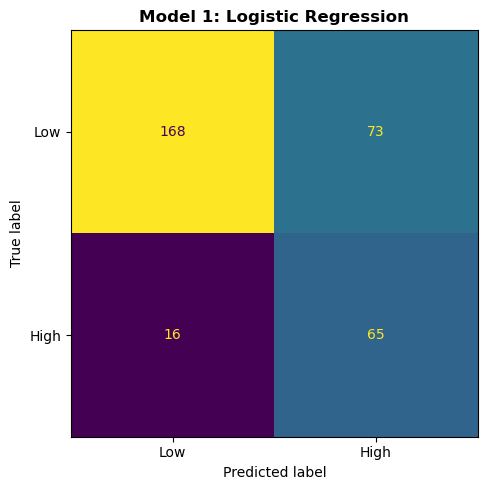

In [18]:
pipe_logreg.fit(X_train, y_train)
preds_pipe_logreg = pipe_logreg.predict(X_test)

print("Model 1: Logistic Regression — held-out test set performance:")
print(classification_report(y_test, preds_pipe_logreg, target_names=['Low', 'High']))

cm_pipe_logreg = confusion_matrix(y_test, preds_pipe_logreg)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm_pipe_logreg, display_labels=['Low', 'High']).plot(ax=ax, colorbar=False)
plt.title('Model 1: Logistic Regression', fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes:**

- High recall on "High" fitness relative to the other models — it correctly identifies more true positives, but at the cost of more false positives (lower precision on "High"). Whether that trade-off is desirable depends on the business context (e.g. a wellness screening tool might prefer to flag more people for a closer look, favouring recall over precision).

#### Model 2: Random Forest

In [19]:
cv_scores_pipe_rf = cross_validate(pipe_rf, X_train, y_train, cv=cv, scoring=scoring)

print("Model 2: Random Forest — 5-fold CV results:")
for metric in scoring:
    scores = cv_scores_pipe_rf[f'test_{metric}']
    print(f"  {metric}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Model 2: Random Forest — 5-fold CV results:
  accuracy: 0.779 (+/- 0.015)
  precision: 0.573 (+/- 0.032)
  recall: 0.495 (+/- 0.055)
  f1: 0.530 (+/- 0.039)
  roc_auc: 0.807 (+/- 0.017)


Model 2: Random Forest — held-out test set performance:
              precision    recall  f1-score   support

         Low       0.86      0.86      0.86       241
        High       0.58      0.58      0.58        81

    accuracy                           0.79       322
   macro avg       0.72      0.72      0.72       322
weighted avg       0.79      0.79      0.79       322



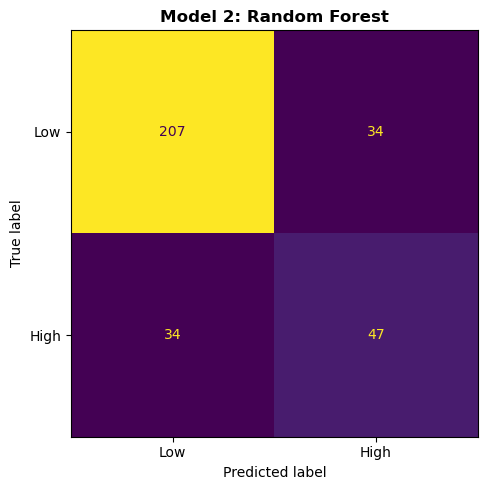

In [20]:
pipe_rf.fit(X_train, y_train)
preds_pipe_rf = pipe_rf.predict(X_test)

print("Model 2: Random Forest — held-out test set performance:")
print(classification_report(y_test, preds_pipe_rf, target_names=['Low', 'High']))

cm_pipe_rf = confusion_matrix(y_test, preds_pipe_rf)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm_pipe_rf, display_labels=['Low', 'High']).plot(ax=ax, colorbar=False)
plt.title('Model 2: Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes:**

- Precision and recall on "High" are more balanced here than Logistic Regression, but recall is noticeably lower — it misses more true "High" cases in exchange for fewer false alarms.
- Worth pulling `pipe_rf.named_steps['clf'].feature_importances_` separately to compare against the correlations found in the Assignment 1 EDA — do the same features (Nutrition Quality, Activity Index, Age) come out as most important here too?

#### Model 3: K-Nearest Neighbors

In [21]:
cv_scores_pipe_knn = cross_validate(pipe_knn, X_train, y_train, cv=cv, scoring=scoring)

print("Model 3: K-Nearest Neighbors — 5-fold CV results:")
for metric in scoring:
    scores = cv_scores_pipe_knn[f'test_{metric}']
    print(f"  {metric}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Model 3: K-Nearest Neighbors — 5-fold CV results:
  accuracy: 0.791 (+/- 0.014)
  precision: 0.690 (+/- 0.040)
  recall: 0.311 (+/- 0.063)
  f1: 0.426 (+/- 0.062)
  roc_auc: 0.792 (+/- 0.016)


Model 3: K-Nearest Neighbors — held-out test set performance:
              precision    recall  f1-score   support

         Low       0.80      0.94      0.86       241
        High       0.63      0.30      0.40        81

    accuracy                           0.78       322
   macro avg       0.72      0.62      0.63       322
weighted avg       0.76      0.78      0.75       322



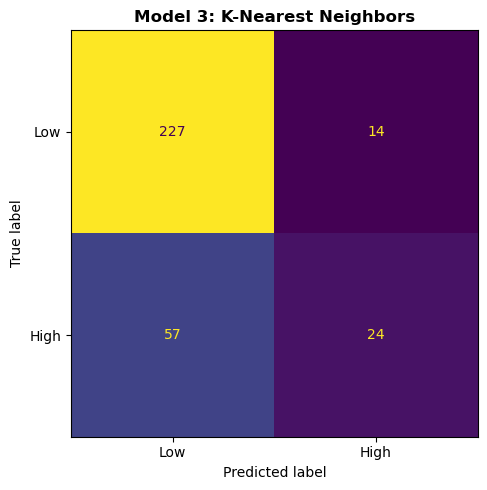

In [22]:
pipe_knn.fit(X_train, y_train)
preds_pipe_knn = pipe_knn.predict(X_test)

print("Model 3: K-Nearest Neighbors — held-out test set performance:")
print(classification_report(y_test, preds_pipe_knn, target_names=['Low', 'High']))

cm_pipe_knn = confusion_matrix(y_test, preds_pipe_knn)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm_pipe_knn, display_labels=['Low', 'High']).plot(ax=ax, colorbar=False)
plt.title('Model 3: K-Nearest Neighbors', fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes**

- Highest raw accuracy of the three models, but by far the lowest recall on "High" (~0.30) — it's mostly just predicting the majority class ("Low") and getting rewarded for it by accuracy, without genuinely discriminating between the two classes. This is the clearest example across all three models of why accuracy alone would have been a misleading metric to rely on.

### Summary comparison across models

In [23]:
summary_rows = []
for name, pipe, preds in [
    ('Logistic Regression', pipe_logreg, preds_pipe_logreg),
    ('Random Forest', pipe_rf, preds_pipe_rf),
    ('K-Nearest Neighbors', pipe_knn, preds_pipe_knn),
]:
    summary_rows.append({
        'Model': name,
        'Test Accuracy': (preds == y_test).mean(),
        'Test Precision (High)': classification_report(y_test, preds, output_dict=True)['1']['precision'],
        'Test Recall (High)': classification_report(y_test, preds, output_dict=True)['1']['recall'],
        'Test F1 (High)': classification_report(y_test, preds, output_dict=True)['1']['f1-score'],
    })

summary_df = pd.DataFrame(summary_rows).round(3)
summary_df

,Model,Test Accuracy,Test Precision (High),Test Recall (High),Test F1 (High)
0,Logistic Regression,0.724,0.471,0.802,0.594
1,Random Forest,0.789,0.580,0.580,0.580
2,K-Nearest Neighbors,0.780,0.632,0.296,0.403


## Discussion of results

You're recommended to add results to a Pandas DataFrame to print out a nice overview table.

Add comments to help your discussion here.


## AI Declaration and Reflection

### AI Tools Declaration

TODO: Add which AI tools/services/models were used and for what

### AI Tools Reflection and Lessons Learnt

TODO: Add a short reflection on your experiences with the AI tools you used (and tools you may have discarded early on), emphasising lessons learnt and key usage patterns that was successful for you.

### AI Academic Integrity

TODO: Add a short statement about how you have ensured academic integrity in this assignment, especially in terms of AI usage. Expected 1 paragraph only.